In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt
from functools import partial
import pprint
# --------------------------------- Internal imports --------------------------------- #
from radiopyo.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo.sim_env import SimEnv
from radiopyo.ode_solver import derive
import radiopyo as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager(csv=False)

np.set_printoptions(precision=3)

In [3]:
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

In [9]:
file = Path(rf"{rp.__path__[0]}\data\reactions_water.ron")
beam = ConstantBeam("e", 10, max_dose=10)
env = SimEnv.from_ron_file(file)

t_span = [1e-8, 10]


In [5]:
beam

ConstantBeam(particle='e', dose_rate=10, timer=Timer(period=inf, on_time=inf), max_dose=10, time_at_max_dose=1.0, dose_per_pulse=inf, peak_dose_rate=10.0)

In [10]:
kwargs = {}
kwargs["max_step"] = np.inf
kwargs["first_step"] = 1e-9
kwargs["atol"] = 1e-5
kwargs["method"] = "BDF" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
y0 = env.initial_values()
ab_mat = env.make_acidBase_matrix()
ki_mat = env.make_kreaction_matrix()
Gi_mat = env.make_radiolytic_vector()
Enzi   = env.make_enzymatic_matrix()

for sp in env.iter_species():
    print(f"{sp.index}) {sp.label} {' '*(20-len(sp.label))} => {y0[sp.index]}\tµmol/l")

0) H2O                   => 55000000.0	µmol/l
1) H_plus                => 0.09999999999999999	µmol/l
2) OH_minus              => 0.09999999999999999	µmol/l
3) OH_r                  => 0.0	µmol/l
4) O_r_minus             => 0.0	µmol/l
5) H2O2                  => 0.0	µmol/l
6) HO2_minus             => 0.0	µmol/l
7) HO2_r                 => 0.0	µmol/l
8) O2_r_minus            => 0.0	µmol/l
9) e_aq                  => 0.0	µmol/l
10) H_r                   => 0.0	µmol/l
11) H2                    => 0.0	µmol/l
12) O2                    => 75.0	µmol/l
13) O2_minus_minus        => 0.0	µmol/l
14) O3_minus              => 0.0	µmol/l


In [28]:
y = np.array(np.arange(1,16))
y

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

In [36]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
print()
matprint(np.prod(res, axis=1).T)


0   0   0   0   0  0   0   0   0   0  0   0   0  0   0   0   0  0   0  0  0  0  0   0  0  
0   0   0   0   0  0   0   0   0   0  0   0   0  0   0   0   0  0   0  0  0  0  0   0  0  
0   0   0   0   0  0   0   0   0   0  0   0   0  0   0   0   0  0   0  0  0  0  0   0  0  
0   0   0  10   0  0   0   0   0   0  0   0  11  0   0   0   0  8  12  3  7  9  0   0  0  
0   0   0   0  10  0   0   0   0   0  0   0   0  0   0   0   0  0   0  0  0  0  1  13  9  
0   0   0   0   0  0  10   0   0   0  0   0   0  0  11   0   0  0   0  0  0  0  0   0  0  
0   0   0   0   0  0   0  10   0   0  0   0   0  0   0   0   0  0   0  0  4  0  0   0  0  
0   0   0   0   0  0   0   0   0   0  0   0   0  0   0   0  11  0   0  0  0  0  0   0  0  
0   0   0   0   0  0   0   0   0  10  0   0   0  0   0   0   0  0   0  0  0  4  0   0  5  
1  20  11   4   5  2   6   7  13   9  0   0   0  0   0   0   0  0   0  0  0  0  0   0  0  
0   0  10   0   0  0   0   0   0   0  1  22   4  3   6  13   8  0   0  0  0  0  0   0  0 

In [30]:
#res = np.einsum("j, jikl -> ikl ", y, ki_mat[3])
for sp in env.iter_species():
    print(f"\n({sp.index:02d}) {sp.label}")
    matprint(res[:,:,sp.index])


(00) H2O
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

(01) H_plus
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

(02) OH_minus
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  
0  0  

(03) OH_r
 0  0  
 0  0  
 0  0  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
11  1  
 0  0  
 0  0  
 0  0  
 0  0  
 8  1  
12  1  
 3  1  
 7  1  
 9  1  
 0  0  
 0  0  
 0  0  

(04) O_r_minus
 0  0  
 0  0  
 0  0  
 0  0  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 1  1  
13  1  
 9  1  

(05) H2O2

In [7]:
for sp in env.iter_species():
    print(f"\n({sp.index:02d}) {sp.label}")
    for idx in range(ki_mat[3].shape[2]):
        matprint(ki_mat[3][:,:,idx,sp.index])
        print("---------------------------------")


(00) H2O
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0 

In [12]:
sol = solve_ivp(derive, t_span, y0, args=(ab_mat, ki_mat, Gi_mat, beam), **kwargs)
time, res = sol.t, sol.y


y(t=1e-08) = [5.5e+01 1.0e-07 1.0e-07 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e-05 0.0e+00 0.0e+00] (before clipping)
===> After A/B: [5.5e+01 1.0e-07 1.0e-07 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e-05 0.0e+00 0.0e+00]
===> dydt From kreactions : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
===> dydt From Radiolytics : [0.0e+00 0.0e+00 0.0e+00 2.9e-06 0.0e+00 7.6e-07 0.0e+00 0.0e+00 0.0e+00
 2.9e-06 6.4e-07 4.9e-07 0.0e+00 0.0e+00 0.0e+00]

y(t=1e-08) = [5.5e+01 1.0e-07 1.0e-07 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e-05 0.0e+00 0.0e+00] (before clipping)
===> After A/B: [5.5e+01 1.0e-07 1.0e-07 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00 0.0e+00
 0.0e+00 0.0e+00 0.0e+00 7.5e-05 0.0e+00 0.0e+00]
===> dydt From kreactions : [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
===> dydt From Radiolytics : [0.0e+00 0.0e+00 0.0e+00 2.9e-06 0.0e+00 7.6e-07 0.0e+00 0.0e+00 0.0e+00
 2.9e-06 6.4e-07 4.9e-07 0.0e+00 0.0e+

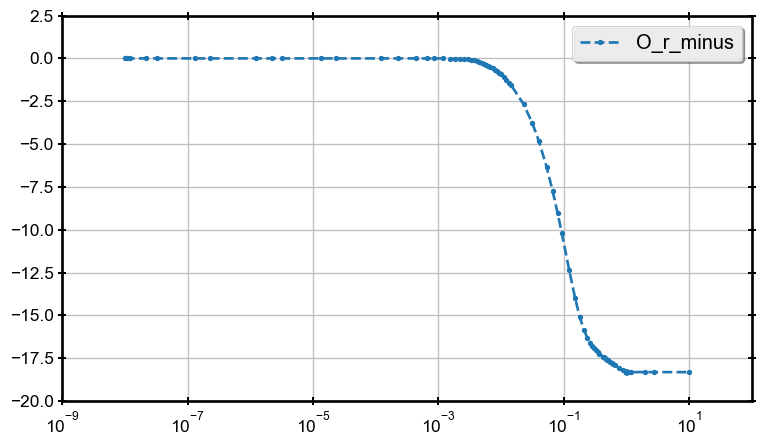

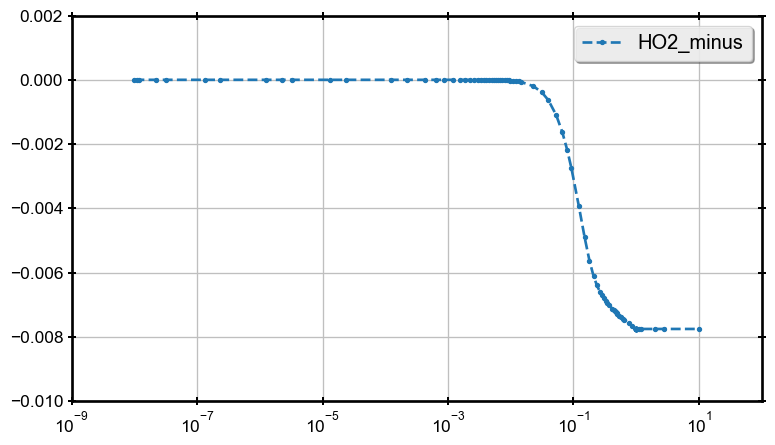

In [13]:
with fig_man.open(f"CC evolution neg species") as (fig, ax):
    ax.semilogx(time, res[4,:], label="O_r_minus")
    ax.legend()
    
with fig_man.open(f"CC evolution neg species") as (fig, ax):
    ax.semilogx(time, res[6,:], label="HO2_minus")
    ax.legend()

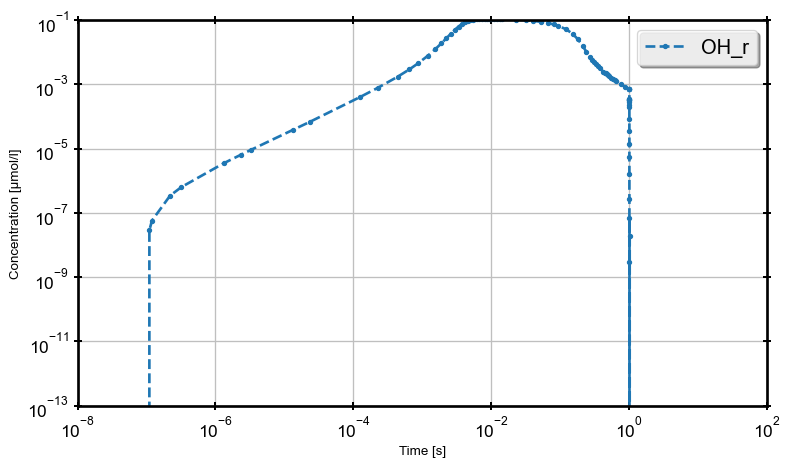

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_14424\3477526452.py:13: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_ylim(bottom=1e-6)


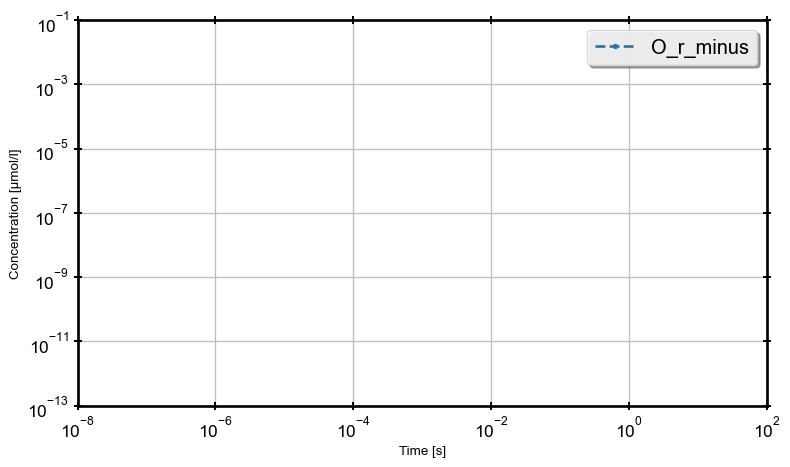

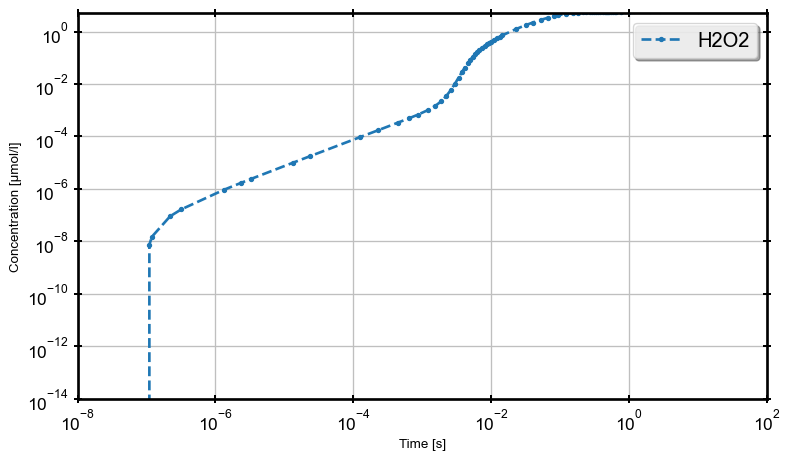

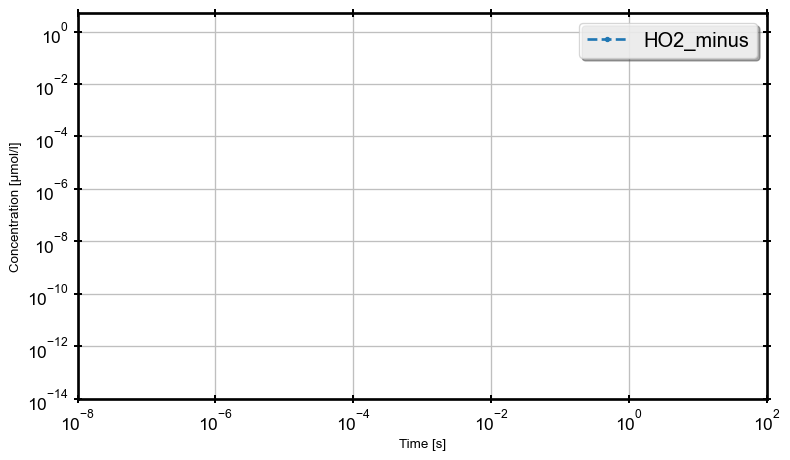

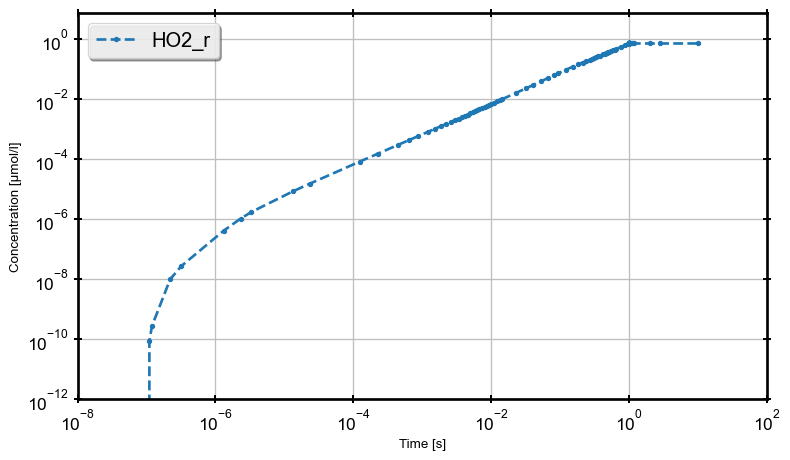

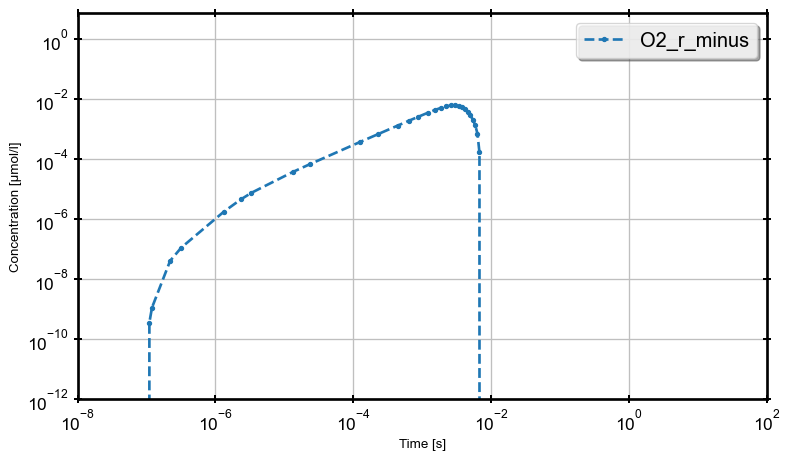

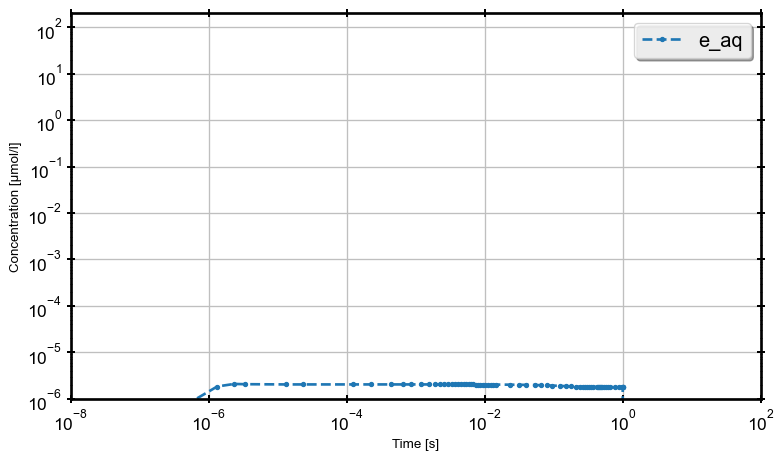

C:\Users\rtonneau\AppData\Local\Temp\ipykernel_14424\3477526452.py:13: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(bottom=1e-6)


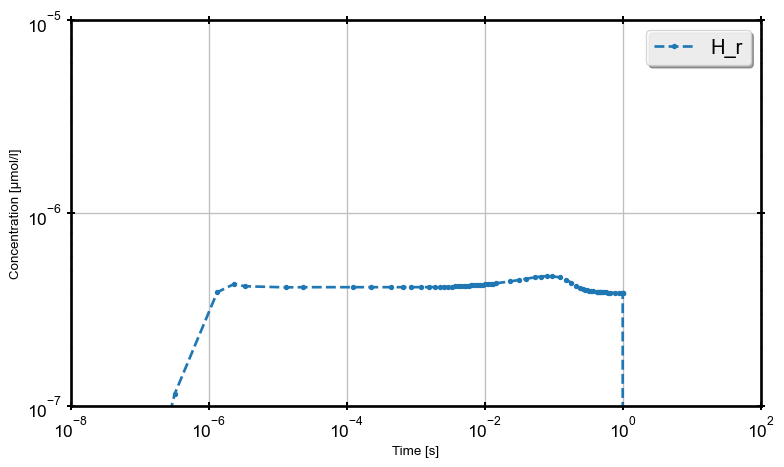

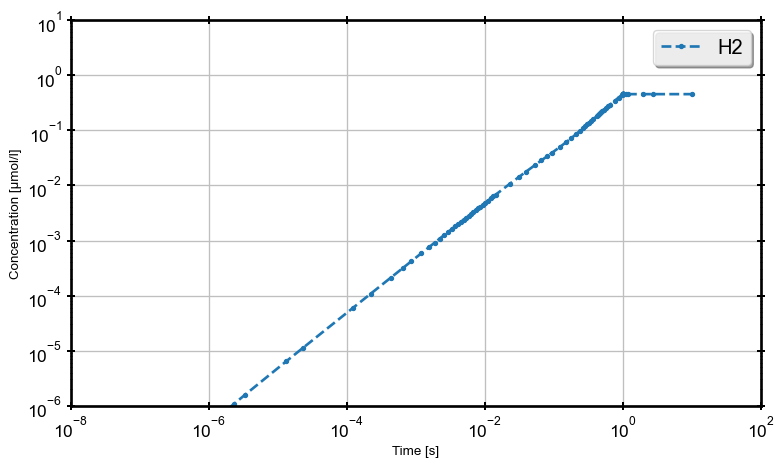

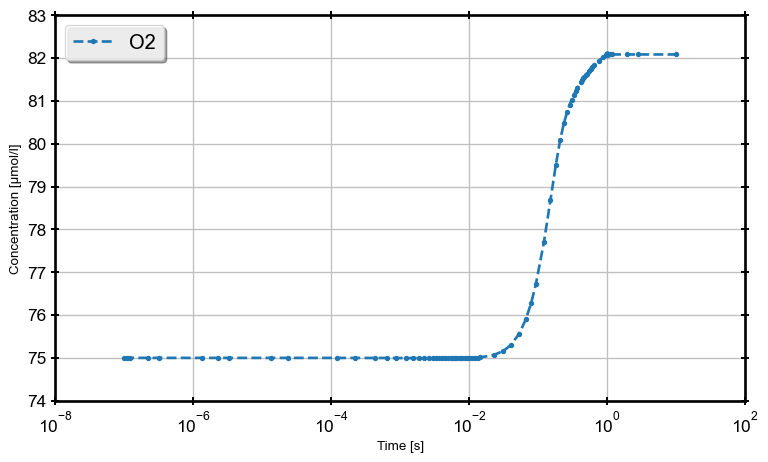

In [9]:
for (label, sp) in zip(env.species_labels(), res):
    if label not in ["e_aq", "H2", "O2", "H_r", "H2O2", "OH_r", "HO2_r", "O_r_minus", "HO2_minus", "O2_r_minus"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        if label=="O2":
            ax.semilogx(time , sp , label=label)
            #ax.set_ylim([74, 76])
        elif label == "e_aq":
            ax.loglog(time , sp , label=label)
            ax.set_ylim([1e-6, 2e2])
        else:
            ax.loglog(time , sp , label=label)
            ax.set_ylim(bottom=1e-6)
        
        if label in ["OH_r", "O_r_minus"]:
            ax.set_ylim([1e-13, 1e-1])
        elif label in ["H2O2", "HO2_minus"]:
            ax.set_ylim([1e-14, 5e0])
        elif label in ["HO2_r", "O2_r_minus"]:
            ax.set_ylim([1e-12, 7e0])
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Debug

In [9]:
from radiopyo.ode_solver import reconstruct_Ri_from_res

df = reconstruct_Ri_from_res(time, res, env, ab_mat, ki_mat, Gi_mat, beam)

In [10]:
df.sum()

R_0          0.0
R_1          0.0
R_2          0.0
R_3          0.0
R_4          0.0
R_5          0.0
R_6     0.000004
R_7          0.0
R_8     0.000194
R_9          0.0
R_10         0.0
R_11         0.0
R_12         0.0
R_13         0.0
R_14         0.0
R_15    0.000046
R_16         0.0
R_17     0.00142
R_18    0.000002
R_19    0.000012
R_20         0.0
R_21    0.000565
R_22    0.003516
R_23     0.00001
R_24         0.0
dtype: object

In [11]:
def get_reactions_related_to(species, env):
    out = set()
    for idx, reaction in enumerate(env.reactions.k_reaction):
        if species in reaction:
            out.add(idx)
    return out
species = {}
for sp in env.iter_species():
    species[sp.label] = get_reactions_related_to(species=sp, env=env)
species

{'H2O': {0, 10, 12, 14, 18, 19, 22},
 'H_plus': {5},
 'OH_minus': {0, 1, 2, 3, 4, 6, 7, 13, 19, 20, 21, 22, 24},
 'OH_r': {3, 6, 7, 10, 12, 14, 17, 18, 19, 20, 21, 22},
 'O_r_minus': {4, 19, 22, 23, 24},
 'H2O2': {6, 14, 16, 17},
 'HO2_minus': {7, 20},
 'HO2_r': {15, 16, 20},
 'O2_r_minus': {8, 9, 21, 24},
 'e_aq': {0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 13},
 'H_r': {0, 2, 5, 10, 11, 12, 13, 14, 15, 16, 18},
 'H2': {1, 2, 10, 11, 18},
 'O2': {8, 15, 21, 23, 24},
 'O2_minus_minus': {9},
 'O3_minus': {23}}

In [16]:
for idx, reaction in enumerate(env.reactions.k_reaction):
    print(f"{idx}) {reaction} {' '*(45-len(reaction.__str__())-len(str(idx)))} k={reaction.k_value:.2g}")

0) e_aq + H2O -> H_r + OH_minus                  k=19
1) 2 e_aq -> H2 + 2 OH_minus                     k=5.5e+09
2) e_aq + H_r -> H2 + OH_minus                   k=1.1e+10
3) e_aq + OH_r -> OH_minus                       k=3e+10
4) e_aq + O_r_minus -> 2 OH_minus                k=2.2e+10
5) e_aq + H_plus -> H_r                          k=2.3e+10
6) e_aq + H2O2 -> OH_minus + OH_r                k=1.1e+10
7) e_aq + HO2_minus -> 2 OH_minus + OH_r         k=3.5e+09
8) e_aq + O2 -> O2_r_minus                       k=1.9e+10
9) e_aq + O2_r_minus -> O2_minus_minus           k=1.3e+10
10) H_r + H2O -> H2 + OH_r                       k=10
11) 2 H_r -> H2                                  k=7.8e+09
12) H_r + OH_r -> H2O                            k=7e+09
13) H_r + OH_minus -> e_aq                       k=2.2e+07
14) H_r + H2O2 -> OH_r + H2O                     k=9e+07
15) H_r + O2 -> HO2_r                            k=2.1e+10
16) H_r + HO2_r -> H2O2                          k=1e+10
17) 2 OH_r -> H

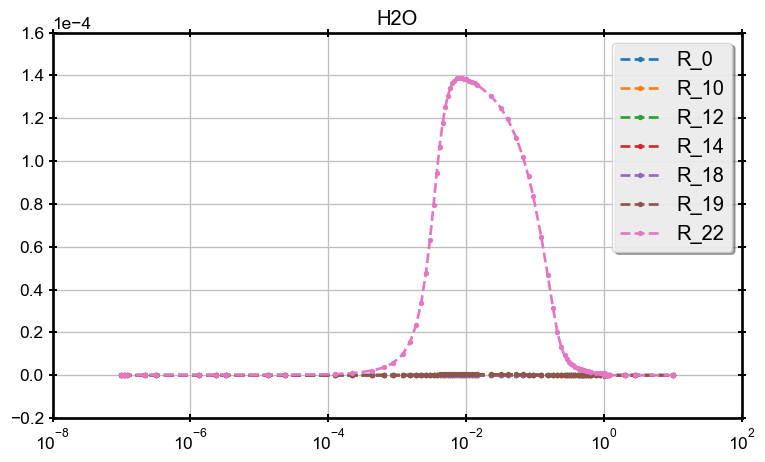

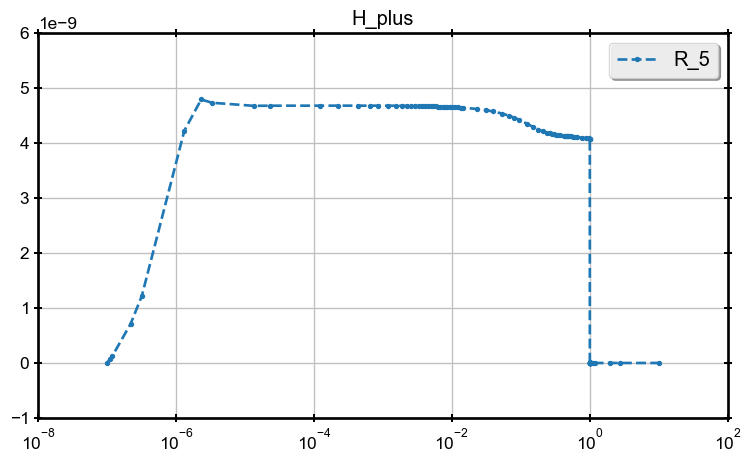

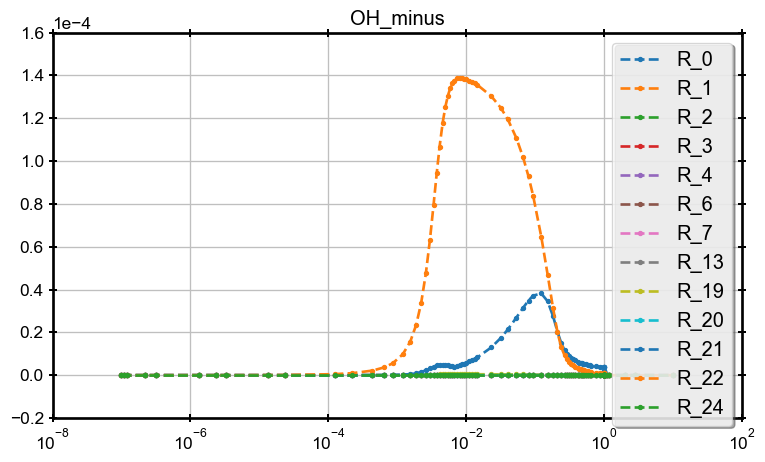

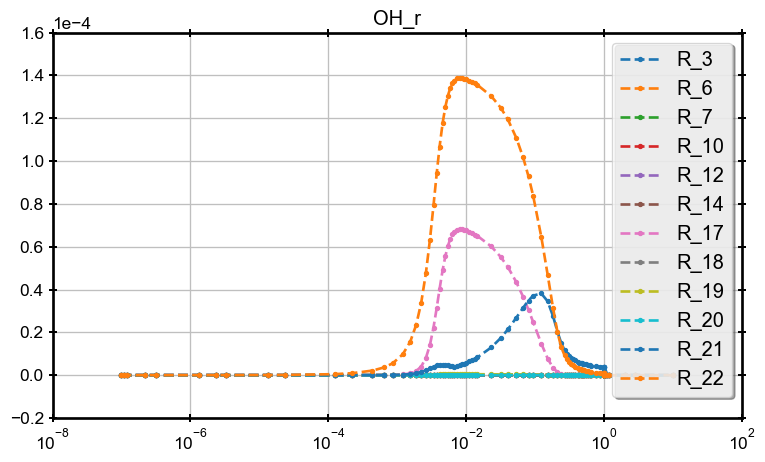

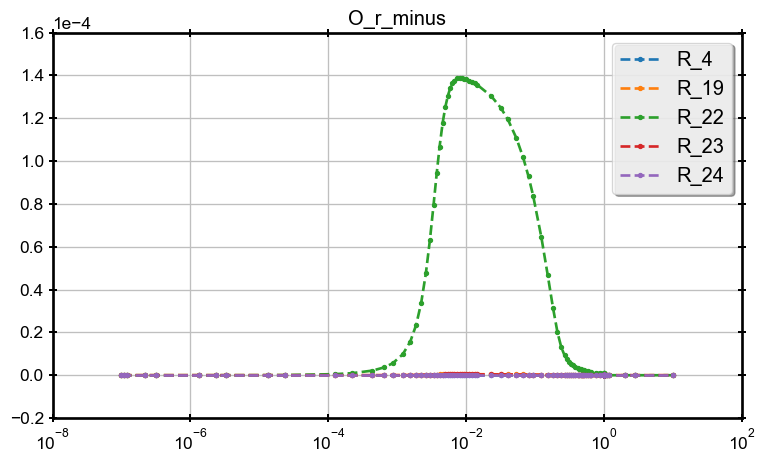

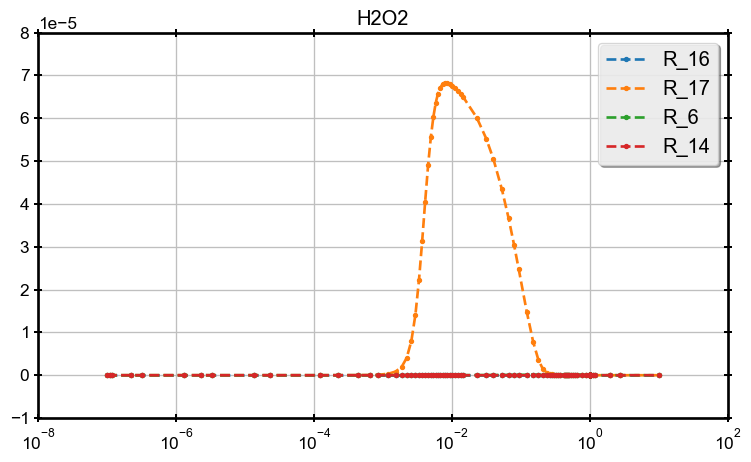

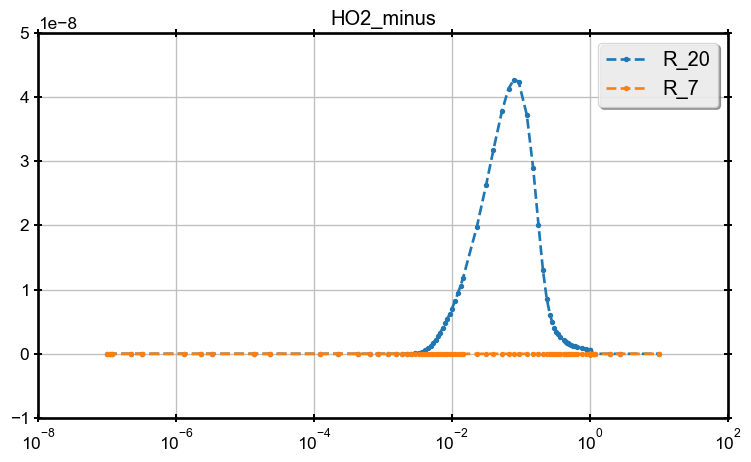

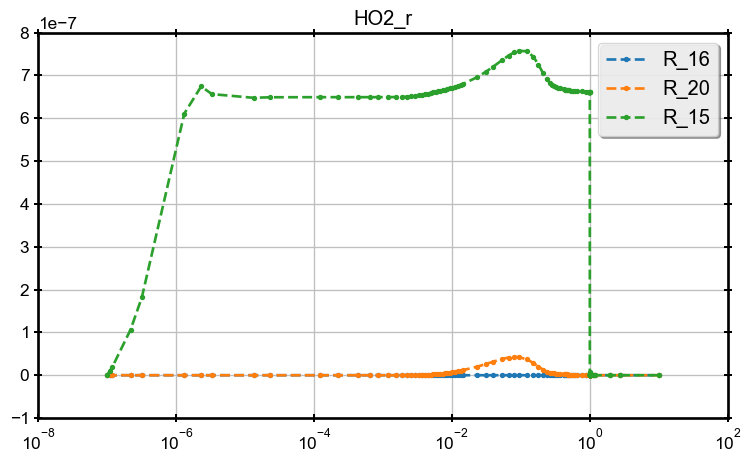

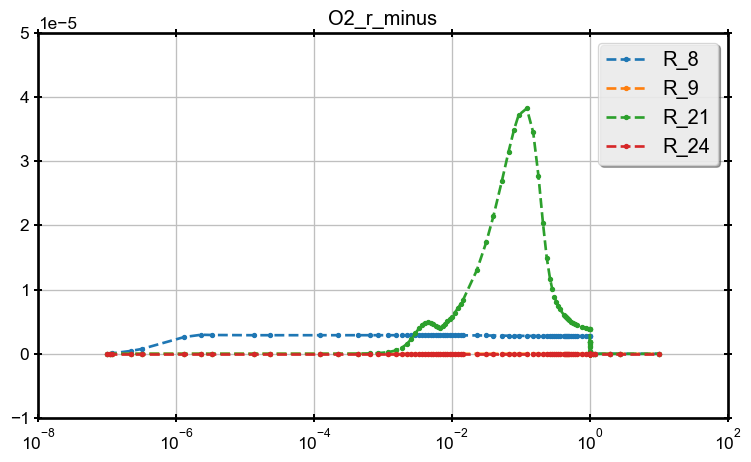

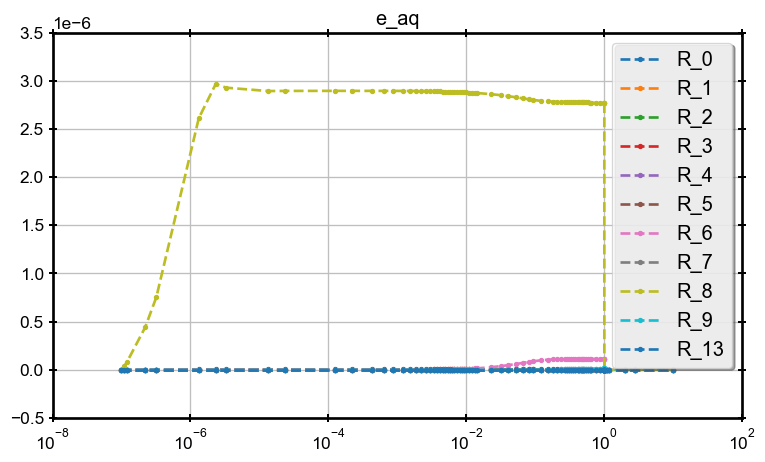

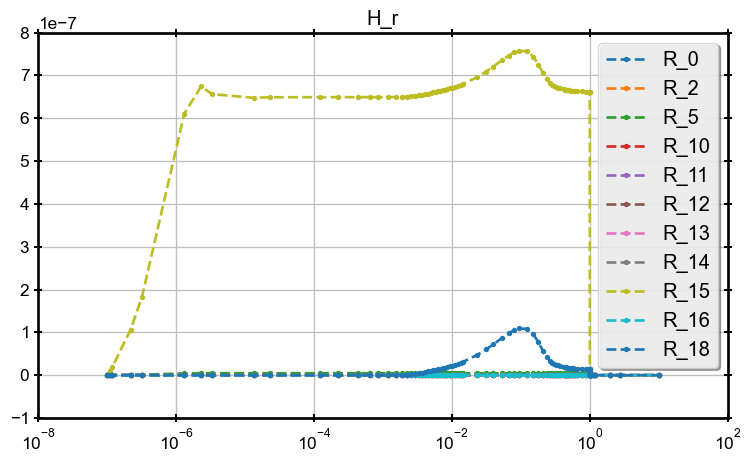

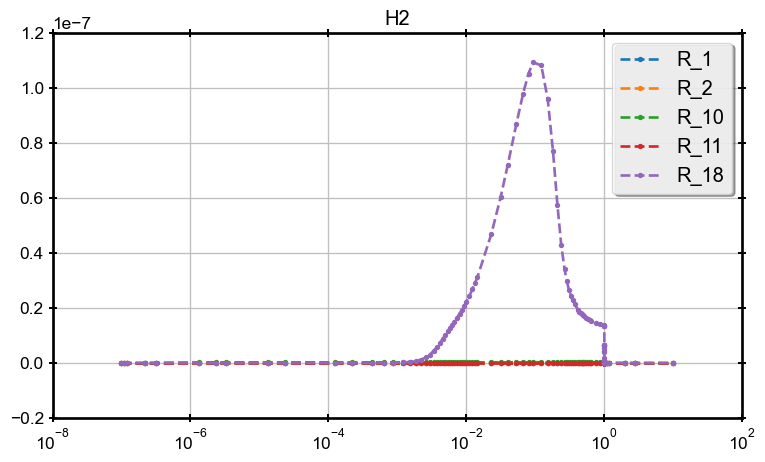

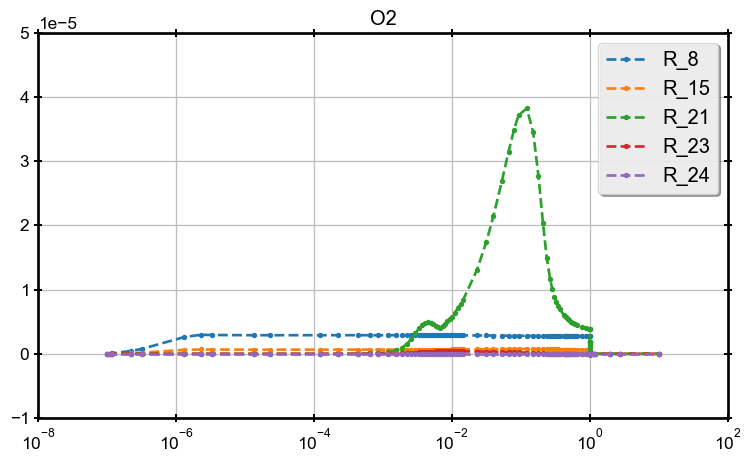

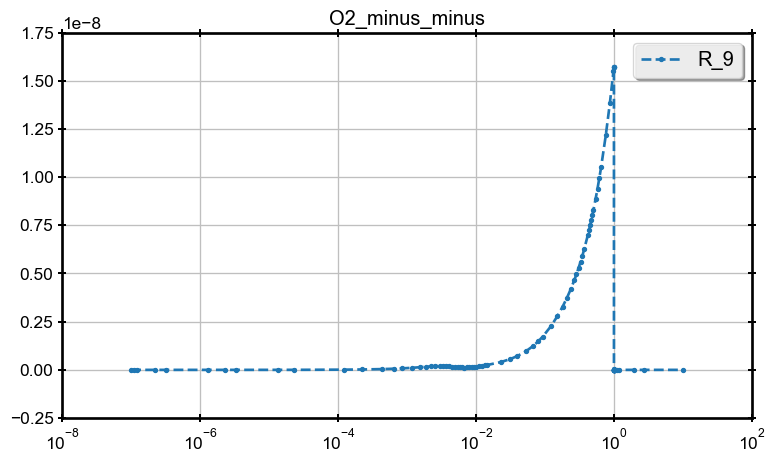

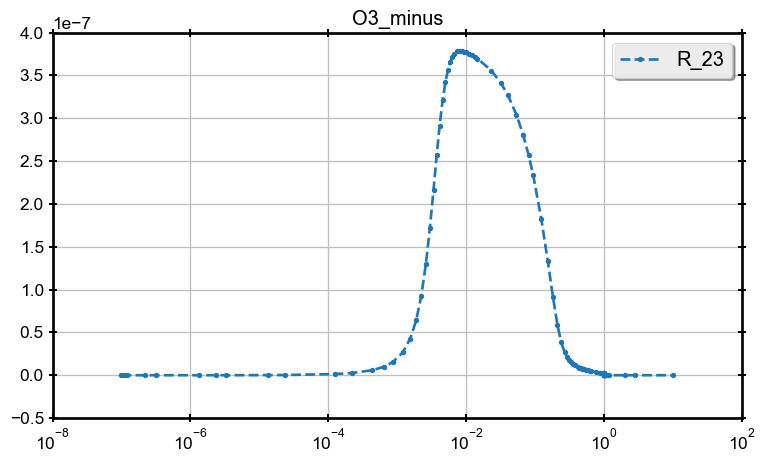

In [12]:
for sp, idx in species.items():
    with fig_man.open(f"Reactions involving {sp}:") as (fig, ax):
        ax.set_title(f"{sp}")
        for elt in idx:
            ax.semilogx(df.index, df[f"R_{elt}"], label=f"R_{elt}")
        ax.legend()

In [16]:
y = np.array([5.500e+01, 1.000e-07, 1.000e-07, 1.624e+01, 0.000e+00, 2.124e+02,
       0.000e+00, 0.000e+00, 0.000e+00, 1.624e+01, 6.439e+00, 2.144e+02,
       7.500e+01, 0.000e+00, 0.000e+00])
Rki = np.einsum("j, jik -> ik ", y, ki_mat[2])
Rki = np.nan_to_num(Rki, nan=1)

In [32]:
ki_mat = env.make_kreaction_matrix()

In [33]:
np.matmul(ki_mat[1], (np.prod(Rki, axis=1) * ki_mat[0]).T)

NameError: name 'Rki' is not defined

In [29]:
ki_mat[0]

array([1.90e+01, 5.50e+09, 1.10e+10, 3.00e+10, 2.20e+10, 2.30e+10,
       1.10e+10, 3.50e+09, 1.90e+10, 1.30e+10, 1.00e+01, 7.75e+09,
       7.00e+09, 2.20e+07, 9.00e+07, 2.10e+10, 1.00e+10, 5.50e+09,
       4.20e+07, 4.20e+07, 7.50e+09, 8.00e+09, 1.80e+06, 3.60e+09,
       6.00e+08])

In [34]:
matprint(ki_mat[2][:,:,0])

0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  1  1  1  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  1  1  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
1  1  1  1  1  1  1  1  1  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  1  1  1  1  1  1  1  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  

In [35]:
matprint(ki_mat[2][:,:,1])

1  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  0  
0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  1  0  0  0  0  0  
0  0  0  1  0  0  0  0  0  0  0  0  1  0  0  0  0  1  0  0  0  0  0  0  0  
0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  1  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  1  0  0  1  
0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  1  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  1  0  0  0  0  0  0  0  1  0  
0  0  0  0  

In [36]:
matprint(ki_mat[1])

 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  
 0   0   0  -1   0   0   1   1   0   0   1   0  -1   0   1   0   0  -2  -1  -1  -1  -1   1   0   0  
 0   0   0   0  -1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  -1  -1  -1  
 0   0   0   0   0   0  -1   0   0   0   0   0   0   0  -1   0   1   1   0   0   0   0   0   0   0  
 0   0   0   0   0   0   0  -1   0   0   0   0   0   0   0   0   0   0   0   0  -1   0   0   0   0  
 0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1  -1   0   0   0   1   0   0   0   0  
 0   0   0   0   0   0   0   0   1  -1   0   0   0   0   0   0   0   0   0   0   0  -1   0   0  -1  
-1  -2  -1  -1  -1  -1  -1  -1  -1  -1   0   0   0   1   0   0   0   0   0   0   0   0   0 

In [26]:
np.matmul(ki_mat[1], (np.prod(Rki, axis=1) * ki_mat[0]).T)

array([ 0.000e+00,  0.000e+00,  0.000e+00,  2.637e+13,  6.821e+08,
       -3.662e+13,  0.000e+00,  1.014e+13,  2.314e+13, -7.342e+13,
       -1.227e+13,  2.776e+12, -3.328e+13,  0.000e+00,  0.000e+00])

## Debug Acid/Base

In [14]:
import numpy as np
from numpy.typing import NDArray
from typing import Tuple

from radiopyo.chemistry.acid_base import ABCouple
from radiopyo.chemistry.species import DynSpecies

In [22]:
cctot = 1e-2
cctot2 = 1
pka = 5.4
ab = ABCouple(acid=DynSpecies("acid",index=1), base=DynSpecies("base",index=2), pKa = pka, index=0)
ab_list = [
    ab,
    ABCouple(acid=DynSpecies("acid",index=3), base=DynSpecies("base",index=4), pKa = 11.9, index=1),
    ABCouple(acid=DynSpecies("acid",index=5), base=DynSpecies("base",index=6), pKa = 5.2, index=2),
]

y0 = np.array([1e-7, cctot-cctot*0.2, cctot-cctot*0.8, cctot2-cctot2*0.5, cctot2-cctot2*0.5, cctot, 0])

In [23]:
ab.compute_partition(cctot, cc_H_plus=1e-7)

ABPartition(A=0.00975496632449664, HA=0.0002450336755033601, dA=0.9754966324496639, dHA=0.02450336755033601)

In [24]:
def make_acidBase_matrix(ab_list, cc_H_plus=1e-7) -> Tuple[NDArray[np.int8],
                                            NDArray[np.int8],
                                            NDArray[np.float64]]:
    n_species = 7 # [H_plus, acid, base]
    ABi = np.zeros([n_species, len(ab_list)],
                   dtype=np.int8)
    ABo = np.zeros_like(ABi, dtype=np.float64)
    ABy = np.zeros(n_species, dtype=np.int8)
    cc_H_plus = cc_H_plus
    for col, reaction in enumerate(ab_list):
        ABi[reaction.acid.index, col] = 1
        ABi[reaction.base.index, col] = 1

        # Get AB partition with cc_tot = 1
        part = reaction.compute_partition(1, cc_H_plus)
        ABo[reaction.acid.index, col] = part.acid
        ABo[reaction.base.index, col] = part.base

    # To remember: operator '^' is bitwise XOR
    # ABy will be use to reset cc values of acid and base in y (see derive)
    ABy = np.logical_and.reduce(ABi ^ 1, axis=1).astype(np.int8)

    return (ABy, ABi, ABo)

In [25]:
ab_mat = make_acidBase_matrix(ab_list)

In [26]:
y0

array([1.e-07, 8.e-03, 2.e-03, 5.e-01, 5.e-01, 1.e-02, 0.e+00])

In [27]:
np.matmul(y0, ab_mat[1]).T

array([0.01, 1.  , 0.01])

In [28]:
ab_mat[0]*y0 + np.matmul(ab_mat[2], np.matmul(y0, ab_mat[1]).T)

array([1.000e-07, 2.450e-04, 9.755e-03, 1.000e+00, 1.259e-05, 1.560e-04,
       9.844e-03])

In [60]:
ab_mat = env.make_acidBase_matrix()
ab_mat[2]

array([[0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [1.000e+00, 0.000e+00, 0.000e+00],
       [1.259e-05, 0.000e+00, 0.000e+00],
       [0.000e+00, 1.000e+00, 0.000e+00],
       [0.000e+00, 1.995e-05, 0.000e+00],
       [0.000e+00, 0.000e+00, 7.881e-03],
       [0.000e+00, 0.000e+00, 9.921e-01],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00],
       [0.000e+00, 0.000e+00, 0.000e+00]])

In [63]:
1/(1+10**(-11.9)/1e-1)

0.9999999999874107

In [62]:
1/(1+1e-7/10**(-11.9))

1.2589095630617651e-05

In [64]:
10**(-11.9)

1.258925411794166e-12